# Backpropagation task

## Steps 1–2: Binary classification dataset
The solution trains a neural network to classify 100 observations using one feature. The target is **class 0 for X < 0** and **class 1 for X ≥ 0**, so the true decision boundary is at zero.

The model uses NumPy for all calculations and Matplotlib for visualisation. The experiments show how learning rate, iteration count, hidden-layer size and activation function affect training. All reported accuracy is training accuracy, rather than an estimate of performance on unseen data.

In [1]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt

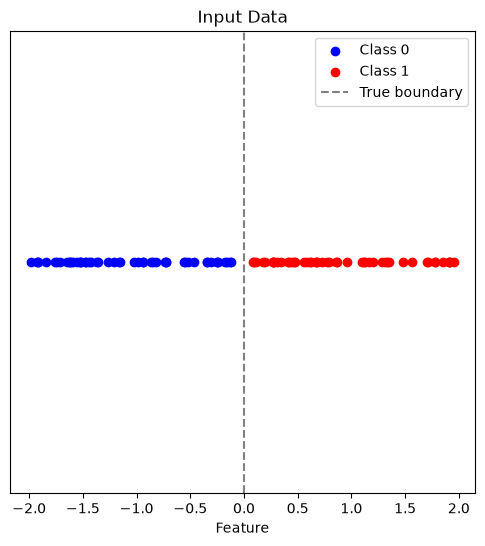

In [ ]:
# Generate synthetic data for classification
np.random.seed(0)
X = np.random.uniform(-2, 2, size=(100, 1))  # 100 samples, 1 feature
y = (X >= 0).astype(int)  # Binary classification: 1 if X >= 0, else 0

# Plot the data
plt.figure(figsize=(6, 6))
plt.scatter(X[y==0], np.zeros_like(X[y==0]), color='blue', label='Class 0')
plt.scatter(X[y==1], np.zeros_like(X[y==1]), color='red', label='Class 1')
plt.title('Input Data')
plt.xlabel('Feature')
plt.yticks([])
plt.axvline(0, color='grey', linestyle='--', label='True boundary')
plt.legend()
plt.show()

## Step 3: Network architecture and parameters
The baseline has **one input, four hidden nodes and one output**. The single sigmoid output represents the probability of class 1, with probabilities ≥ 0.5 classified as class 1. Binary classification therefore needs only one output node here.

Small random weights and biases break symmetry between hidden nodes. The parameter shapes are W1: (1, 4), b1: (1, 4), W2: (4, 1) and b2: (1, 1). Biases allow the activations to shift independently of the input.

The baseline uses **1000 iterations** and a **learning rate of 0.1**. Each iteration uses all observations, making it a full-batch epoch. The learning rate determines the size of each gradient-descent update. Small values can learn slowly; excessively large values can cause unstable updates.

In [ ]:
# Sigmoid activation function and its derivative
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def sigmoid_derivative(x):
    return sigmoid(x) * (1 - sigmoid(x))


# Initialise network dimensions.
input_size = 1
hidden_size = 4
output_size = 1


def initialise_parameters(hidden_size):
    # Resetting a local generator gives reproducible starting parameters.
    rng = np.random.RandomState(42)
    W1 = rng.randn(input_size, hidden_size) * 0.1
    b1 = rng.randn(1, hidden_size) * 0.1
    W2 = rng.randn(hidden_size, output_size) * 0.1
    b2 = rng.randn(1, output_size) * 0.1
    return W1, b1, W2, b2


W1, b1, W2, b2 = initialise_parameters(hidden_size)

# Training parameters
num_iter = 1000
learning_rate = 0.1

## Step 4: Training with backpropagation
The forward pass calculates hidden activations and then a sigmoid output probability. **Binary cross-entropy (BCE)** measures the prediction error:

L = −mean[y log(A2) + (1 − y) log(1 − A2)].

The equivalent expression `logaddexp(0, Z2) - y * Z2` computes BCE directly from the output weighted sums, avoiding log(0).

For sigmoid combined with BCE, the output gradient simplifies to **dZ2 = (A2 − y) / n**. This already includes the output sigmoid derivative and the averaging over observations. The hidden gradient uses the chain rule: **dZ1 = dA1 × sigmoid_derivative(Z1)**. All weight and bias gradients are calculated before updating any parameter.

Loss is recorded before each update. The final predictions and metrics are recalculated after the last update.

In [ ]:
# Training loop
losses = []
for iteration in range(num_iter):
    # Forward pass
    Z1 = np.dot(X, W1) + b1
    A1 = sigmoid(Z1)
    Z2 = np.dot(A1, W2) + b2
    A2 = sigmoid(Z2)
    y_pred = A2

    # Binary cross-entropy, evaluated in a numerically stable form.
    loss = np.mean(np.logaddexp(0, Z2) - y * Z2)
    losses.append(float(loss))

    # Backward pass: average once, in dZ2.
    dZ2 = (A2 - y) / len(y)
    dW2 = np.dot(A1.T, dZ2)
    db2 = np.sum(dZ2, axis=0, keepdims=True)
    dA1 = np.dot(dZ2, W2.T)
    dZ1 = dA1 * sigmoid_derivative(Z1)
    dW1 = np.dot(X.T, dZ1)
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    # Update weights and biases using gradient descent.
    W1 = W1 - learning_rate * dW1
    b1 = b1 - learning_rate * db1
    W2 = W2 - learning_rate * dW2
    b2 = b2 - learning_rate * db2

    if iteration % 100 == 0:
        print(f'Iteration {iteration}, Loss: {loss:.4f}')

# Recompute predictions using the final parameters.
Z1 = np.dot(X, W1) + b1
A1 = sigmoid(Z1)
Z2 = np.dot(A1, W2) + b2
y_pred = sigmoid(Z2)
final_loss = np.mean(np.logaddexp(0, Z2) - y * Z2)
accuracy = np.mean((y_pred >= 0.5) == y)
print(f'Final BCE: {final_loss:.4f}; training accuracy: {accuracy:.1%}')

Iteration 0, Loss: 0.6946
Iteration 100, Loss: 0.6904
Iteration 200, Loss: 0.6665
Iteration 300, Loss: 0.5465
Iteration 400, Loss: 0.3597
Iteration 500, Loss: 0.2364
Iteration 600, Loss: 0.1709
Iteration 700, Loss: 0.1334
Iteration 800, Loss: 0.1097
Iteration 900, Loss: 0.0933
Final BCE: 0.0814; training accuracy: 100.0%


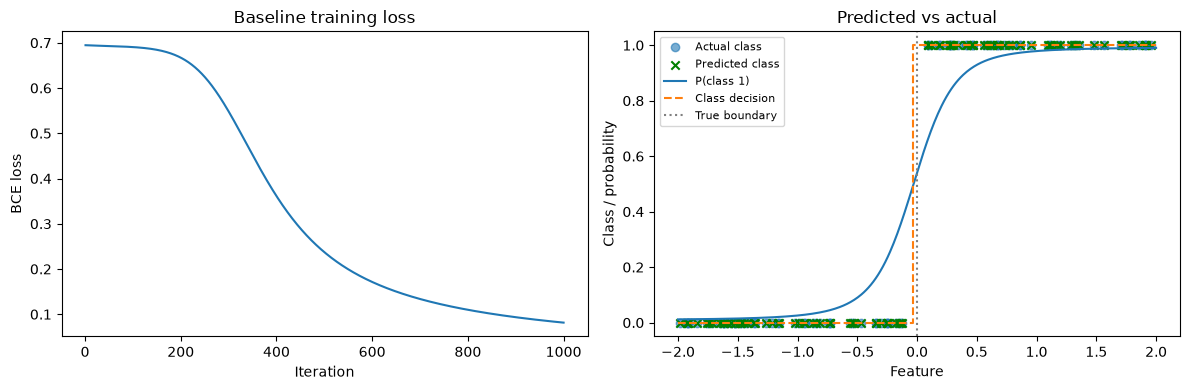

In [ ]:
# Plot training loss and compare predictions with actual classes.
x_grid = np.linspace(-2, 2, 400).reshape(-1, 1)
grid_probabilities = sigmoid(np.dot(sigmoid(np.dot(x_grid, W1) + b1), W2) + b2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(np.arange(1, num_iter + 1), losses)
axes[0].set(xlabel='Iteration', ylabel='BCE loss', title='Baseline training loss')
axes[1].scatter(X[:, 0], y[:, 0], alpha=0.6, label='Actual class')
axes[1].scatter(X[:, 0], (y_pred[:, 0] >= 0.5), color='green',
                marker='x', label='Predicted class')
axes[1].plot(x_grid[:, 0], grid_probabilities[:, 0], label='P(class 1)')
axes[1].step(x_grid[:, 0], (grid_probabilities[:, 0] >= 0.5).astype(int),
             where='mid', linestyle='--', label='Class decision')
axes[1].axvline(0, color='grey', linestyle=':', label='True boundary')
axes[1].set(xlabel='Feature', ylabel='Class / probability', title='Predicted vs actual')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Baseline result
The baseline reaches 100% training accuracy with a final BCE of approximately 0.0814. Its probability curve transitions near the true boundary at zero. The declining loss shows that the probabilities become more consistent with the labels during training.

## Step 5: Learning rates and iteration counts
The next experiment compares all six combinations of learning rates **0.001, 0.1 and 1.0** with **500 and 2000 iterations**. Every run starts with identical parameters and uses the same data.

A reusable training function applies the same forward pass, loss, gradients and updates as the completed loop above. It also supports tanh in the hidden layer for the later activation experiment. The output remains sigmoid in every experiment.

In [ ]:
def hidden_activation(z, activation):
    if activation == 'sigmoid':
        return sigmoid(z)
    if activation == 'tanh':
        return np.tanh(z)
    raise ValueError('Choose sigmoid or tanh')


def hidden_derivative(z, activation):
    if activation == 'sigmoid':
        return sigmoid_derivative(z)
    if activation == 'tanh':
        return 1 - np.tanh(z)**2
    raise ValueError('Choose sigmoid or tanh')


def predict_probability(X, parameters, activation='sigmoid'):
    W1, b1, W2, b2 = parameters
    Z1 = np.dot(X, W1) + b1
    A1 = hidden_activation(Z1, activation)
    Z2 = np.dot(A1, W2) + b2
    return sigmoid(Z2)


def train_network(X, y, hidden_size=4, learning_rate=0.1,
                  num_iterations=1000, activation='sigmoid'):
    W1, b1, W2, b2 = initialise_parameters(hidden_size)
    losses = []
    for iteration in range(num_iterations):
        Z1 = np.dot(X, W1) + b1
        A1 = hidden_activation(Z1, activation)
        Z2 = np.dot(A1, W2) + b2
        A2 = sigmoid(Z2)
        loss = np.mean(np.logaddexp(0, Z2) - y * Z2)
        losses.append(float(loss))

        dZ2 = (A2 - y) / len(y)
        dW2 = np.dot(A1.T, dZ2)
        db2 = np.sum(dZ2, axis=0, keepdims=True)
        dA1 = np.dot(dZ2, W2.T)
        dZ1 = dA1 * hidden_derivative(Z1, activation)
        dW1 = np.dot(X.T, dZ1)
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        W1 = W1 - learning_rate * dW1
        b1 = b1 - learning_rate * db1
        W2 = W2 - learning_rate * dW2
        b2 = b2 - learning_rate * db2
    return (W1, b1, W2, b2), losses


def evaluate(X, y, parameters, activation='sigmoid'):
    W1, b1, W2, b2 = parameters
    A1 = hidden_activation(np.dot(X, W1) + b1, activation)
    Z2 = np.dot(A1, W2) + b2
    loss = np.mean(np.logaddexp(0, Z2) - y * Z2)
    accuracy = np.mean((sigmoid(Z2) >= 0.5) == y)
    return float(loss), float(accuracy)

Learning rate | Iterations | Final BCE | Training accuracy


        0.001 |        500 |    0.6944 |            51.0%
        0.100 |        500 |    0.2364 |           100.0%
        1.000 |        500 |    0.0140 |           100.0%
        0.001 |       2000 |    0.6938 |            51.0%
        0.100 |       2000 |    0.0367 |           100.0%


        1.000 |       2000 |    0.0031 |           100.0%


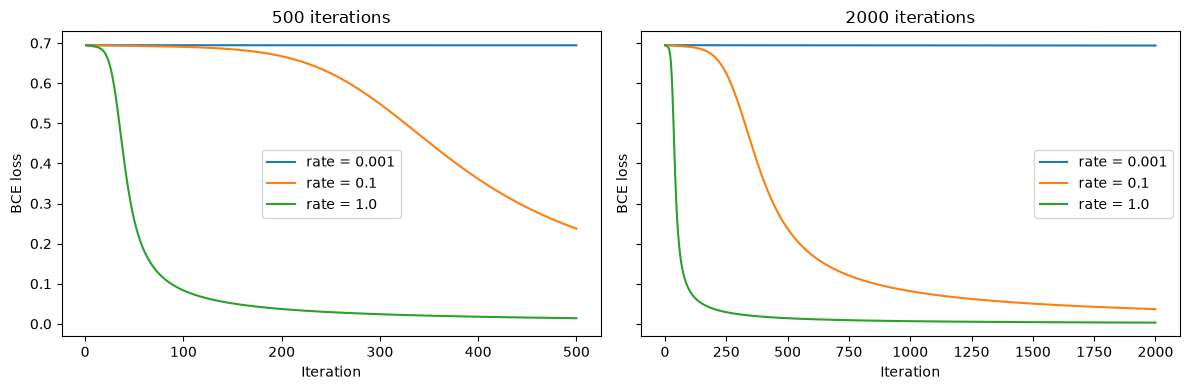

In [ ]:
rate_results = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
print('Learning rate | Iterations | Final BCE | Training accuracy')
for ax, iterations in zip(axes, [500, 2000]):
    for rate in [0.001, 0.1, 1.0]:
        model, history = train_network(X, y, learning_rate=rate,
                                       num_iterations=iterations)
        loss, acc = evaluate(X, y, model)
        rate_results.append((rate, iterations, loss, acc))
        print(f'{rate:13.3f} | {iterations:10d} | {loss:9.4f} | {acc:16.1%}')
        ax.plot(np.arange(1, iterations + 1), history, label=f'rate = {rate}')
    ax.set(xlabel='Iteration', ylabel='BCE loss', title=f'{iterations} iterations')
    ax.legend()
plt.tight_layout()
plt.show()

### Learning-rate and iteration results
Rate 0.001 makes little progress: BCE remains close to 0.69 and accuracy is 51% with both iteration counts. The updates are too small to learn the boundary within these budgets. This is an under-trained fit, rather than evidence that the network lacks capacity.

Rates 0.1 and 1.0 converge stably, with lower losses after 2000 iterations than after 500. Rate 1.0 with 2000 iterations gives the lowest BCE, approximately 0.0031, and 100% training accuracy. Rate 0.1 also reaches 100% accuracy, but its higher BCE reflects less confident predictions.

No overshooting is observed for these settings. Larger learning rates can cause oscillation or divergence, but that behaviour is not demonstrated by these runs.

## Step 6: Hidden-layer size
The models below use **2, 4 and 8 hidden nodes**, with sigmoid, rate 0.1 and 2000 iterations fixed. The seed is the same across runs, although changing matrix shapes changes the starting parameter arrays.

Hidden nodes | Parameters | Final BCE | Training accuracy
           2 |          7 |    0.0463 |           100.0%


           4 |         13 |    0.0367 |           100.0%


           8 |         25 |    0.0341 |           100.0%


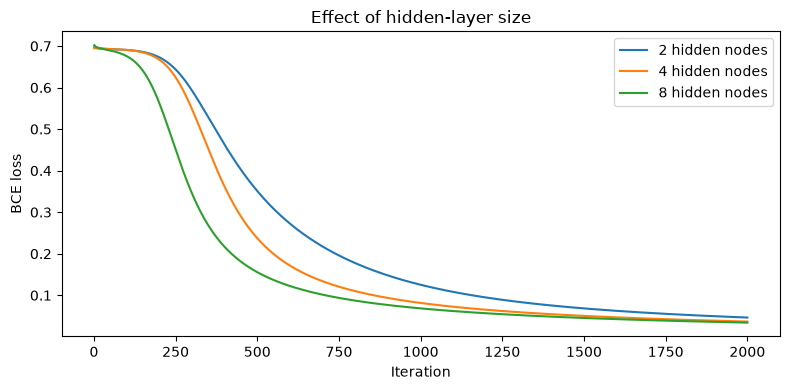

In [ ]:
node_results = []
print('Hidden nodes | Parameters | Final BCE | Training accuracy')
plt.figure(figsize=(8, 4))
for nodes in [2, 4, 8]:
    model, history = train_network(X, y, hidden_size=nodes,
                                   learning_rate=0.1, num_iterations=2000)
    loss, acc = evaluate(X, y, model)
    count = sum(parameter.size for parameter in model)
    node_results.append((nodes, count, loss, acc))
    print(f'{nodes:12d} | {count:10d} | {loss:9.4f} | {acc:16.1%}')
    plt.plot(np.arange(1, len(history) + 1), history, label=f'{nodes} hidden nodes')
plt.xlabel('Iteration')
plt.ylabel('BCE loss')
plt.title('Effect of hidden-layer size')
plt.legend()
plt.tight_layout()
plt.show()

### Hidden-layer results
All three sizes reach 100% training accuracy. Their final BCE values are approximately 0.0463, 0.0367 and 0.0341 for 2, 4 and 8 nodes respectively. Eight nodes achieve a slightly lower training loss, but four nodes are sufficient for this simple threshold problem.

The models have 7, 13 and 25 trainable parameters respectively. More hidden nodes increase capacity and computation per update. Extra capacity can help model more complex patterns, but can also fit noise. This training-only experiment does not demonstrate overfitting; assessing it would require validation data. Differences at one seed and training budget do not establish that larger networks are always better.

## Step 7: Hidden activation function
The alternative hidden activation is **tanh(z)**, with derivative **1 − tanh²(z)**. Both models retain a sigmoid output, four hidden nodes, rate 0.1 and 1000 iterations. They start with identical parameters, isolating the change in hidden activation.

Hidden activation | Final BCE | Training accuracy


sigmoid           |    0.0814 |           100.0%
tanh              |    0.0175 |           100.0%


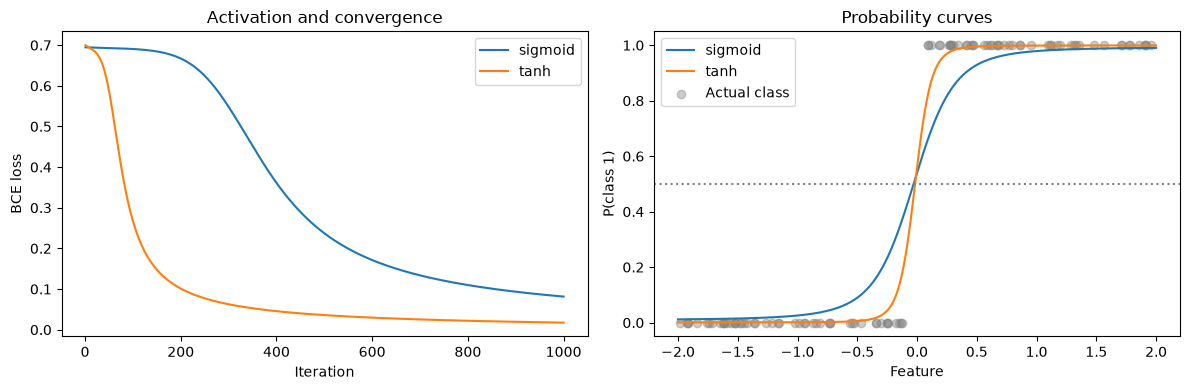

In [ ]:
activation_results = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
print('Hidden activation | Final BCE | Training accuracy')
for activation in ['sigmoid', 'tanh']:
    model, history = train_network(X, y, activation=activation,
                                   learning_rate=0.1, num_iterations=1000)
    loss, acc = evaluate(X, y, model, activation)
    activation_results.append((activation, loss, acc))
    print(f'{activation:17s} | {loss:9.4f} | {acc:16.1%}')
    axes[0].plot(np.arange(1, len(history) + 1), history, label=activation)
    probabilities = predict_probability(x_grid, model, activation)
    axes[1].plot(x_grid[:, 0], probabilities[:, 0], label=activation)
axes[0].set(xlabel='Iteration', ylabel='BCE loss', title='Activation and convergence')
axes[1].scatter(X[:, 0], y[:, 0], color='grey', alpha=0.4, label='Actual class')
axes[1].axhline(0.5, color='grey', linestyle=':')
axes[1].set(xlabel='Feature', ylabel='P(class 1)', title='Probability curves')
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

### Activation results
Tanh converges faster in this experiment and produces a sharper probability transition near zero. Both models reach 100% training accuracy, but tanh has a lower final BCE (approximately 0.0175) than sigmoid (0.0814). The predicted classes agree with the labels in both cases, while tanh gives greater confidence to the correct classes.

Near zero, the tanh derivative is 1, whereas the sigmoid derivative is at most 0.25. The small initial weights place many hidden inputs near zero, allowing tanh to pass stronger gradients early in training. Tanh outputs are also centred around zero. Both functions saturate for large absolute inputs, so both can still produce small gradients.

These results show how the training settings affect convergence on this dataset. They do not establish a universally best activation or configuration.